# Korpus aufbauen

In [1]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.model_selection import KFold, cross_val_score
import sklearn.metrics as metrics
import pandas as pd
import matplotlib.pyplot as plt
import os
import nltk
from nltk.text import Text
from nltk.tokenize import word_tokenize
from nltk.probability import FreqDist
from nltk.util import ngrams
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_distances, cosine_similarity
import numpy as np
import spacy
from textstat.textstat import textstatistics
import pyphen
import re
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn import svm

import sys
sys.path.append("..")   # Projektordner, damit Python den Ordner src findet
from src.features import FEATURES, feature_table, load_corpus

corpus = list(load_corpus("../data/corpus").values())   # die Texte, für die n-Gramm-Zellen
corp = feature_table("../data/corpus")                   # eine Zeile pro Text: file, author, 12 Merkmale
colu = FEATURES
corp

,file,author,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,FRE_Ger,TTR,Avg !,Avg ?,Avg .,"Avg ,",Avg ;,Avg :
0,achleitner-Aus_Kroatien,Achleitner,5.8,15.7,1.9,9.10,53.15,0.21,0.013,0.003,0.036,0.061,0.005,0.003
1,achleitner-Bergrichters_Erdenwallen,Achleitner,5.5,13.2,1.8,7.18,61.50,0.17,0.022,0.007,0.032,0.062,0.001,0.002
2,achleitner-Celsissimus,Achleitner,5.5,17.9,1.8,8.14,56.80,0.16,0.018,0.004,0.024,0.070,0.002,0.004
3,achleitner-Im_gruenen_Tann,Achleitner,5.3,16.3,1.7,6.91,64.25,0.17,0.017,0.004,0.030,0.066,0.004,0.004
4,achleitner-Unter_den_Hohen_Tauern,Achleitner,5.5,12.6,1.8,7.47,62.10,0.15,0.032,0.005,0.028,0.063,0.002,0.005
5,anonymous-Der Luftpirat und sein lenkbares Luf...,Anonymous,5.4,16.4,1.7,7.33,64.15,0.21,0.004,0.002,0.042,0.088,0.000,0.000
6,anonymous-Der Luftpirat und sein lenkbares Luf...,Anonymous,5.3,13.5,1.8,6.98,61.20,0.20,0.001,0.003,0.050,0.074,0.000,0.000
7,anonymous-Der Luftpirat und sein lenkbares Luf...,Anonymous,5.4,15.5,1.8,7.85,59.20,0.20,0.001,0.002,0.048,0.075,0.000,0.000
8,anonymous-Der Luftpirat und sein lenkbares Luf...,Anonymous,5.4,15.1,1.8,7.58,59.60,0.21,0.001,0.001,0.051,0.072,0.000,0.000
9,anonymous-Der Luftpirat und sein lenkbares Luf...,Anonymous,5.5,13.6,1.8,7.50,61.10,0.21,0.001,0.001,0.054,0.073,0.000,0.000


In [2]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(analyzer='word', ngram_range=(1, 2), binary=True)
X = vectorizer.fit_transform(corpus)

In [3]:
dist_matrix = cosine_distances(X)

for i, text in enumerate(corpus):
    print(f"Vektor für Text {i} →",
          X[i].toarray().reshape(-1)[:37]) 

print("\nCosine-Distanz-Matrix:")
print(dist_matrix)

Vektor für Text 0 → [1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 1 → [1 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 1 1 0 1 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 2 → [1 0 1 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 0 0 1 1 1 1 1 0 1 1 1 0]
Vektor für Text 3 → [1 0 0 0 1 0 0 0 0 0 0 0 0 0 1 1 0 0 1 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 4 → [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 1]
Vektor für Text 5 → [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 6 → [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 7 → [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 8 → [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 9 → [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vektor für Text 10 → [0 0 0 0 0 0 0 0 0 

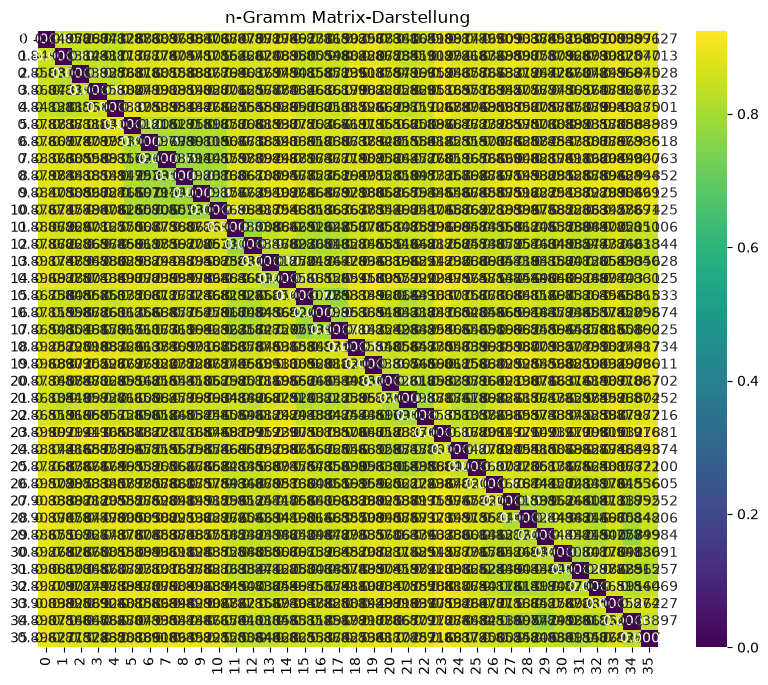

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame(dist_matrix)

plt.figure(figsize=(10, 8))
sns.heatmap(df, annot=True, fmt=".5f", cmap="viridis")
plt.title("n-Gramm Matrix-Darstellung")
plt.show()


In [5]:
corpus_vec = corp[colu].to_numpy()
corpus_matrix = cosine_distances(corpus_vec)

In [6]:
corpus_matrix = cosine_distances(corpus_vec)
corpus_matrix

array([[0.00000000e+00, 4.12609557e-03, 5.91865835e-04, ...,
        2.62061784e-02, 2.90535281e-02, 2.37706419e-02],
       [4.12609557e-03, 0.00000000e+00, 4.55087314e-03, ...,
        9.58894725e-03, 1.13532767e-02, 8.13029901e-03],
       [5.91865835e-04, 4.55087314e-03, 0.00000000e+00, ...,
        2.63964633e-02, 2.93918825e-02, 2.39236990e-02],
       ...,
       [2.62061784e-02, 9.58894725e-03, 2.63964633e-02, ...,
        0.00000000e+00, 8.67507082e-05, 6.89283336e-05],
       [2.90535281e-02, 1.13532767e-02, 2.93918825e-02, ...,
        8.67507082e-05, 0.00000000e+00, 2.95420809e-04],
       [2.37706419e-02, 8.13029901e-03, 2.39236990e-02, ...,
        6.89283336e-05, 2.95420809e-04, 0.00000000e+00]], shape=(36, 36))

# Heatmap zeichnen

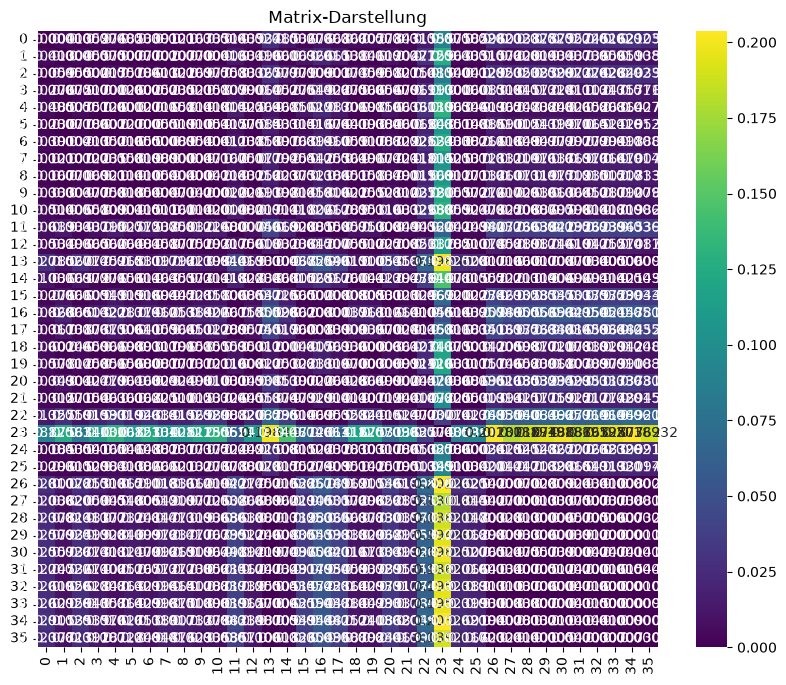

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame(corpus_matrix)

plt.figure(figsize=(10, 8))
sns.heatmap(df, annot=True, fmt=".5f", cmap="viridis")
plt.title("Matrix-Darstellung")
plt.show()


-----------------------------------------------------------------

# Decision Tree

In [8]:
X = corp[colu] # Features
y = corp["author"] # Target variable

In [9]:
corp

,file,author,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,FRE_Ger,TTR,Avg !,Avg ?,Avg .,"Avg ,",Avg ;,Avg :
0,achleitner-Aus_Kroatien,Achleitner,5.8,15.7,1.9,9.10,53.15,0.21,0.013,0.003,0.036,0.061,0.005,0.003
1,achleitner-Bergrichters_Erdenwallen,Achleitner,5.5,13.2,1.8,7.18,61.50,0.17,0.022,0.007,0.032,0.062,0.001,0.002
2,achleitner-Celsissimus,Achleitner,5.5,17.9,1.8,8.14,56.80,0.16,0.018,0.004,0.024,0.070,0.002,0.004
3,achleitner-Im_gruenen_Tann,Achleitner,5.3,16.3,1.7,6.91,64.25,0.17,0.017,0.004,0.030,0.066,0.004,0.004
4,achleitner-Unter_den_Hohen_Tauern,Achleitner,5.5,12.6,1.8,7.47,62.10,0.15,0.032,0.005,0.028,0.063,0.002,0.005
5,anonymous-Der Luftpirat und sein lenkbares Luf...,Anonymous,5.4,16.4,1.7,7.33,64.15,0.21,0.004,0.002,0.042,0.088,0.000,0.000
6,anonymous-Der Luftpirat und sein lenkbares Luf...,Anonymous,5.3,13.5,1.8,6.98,61.20,0.20,0.001,0.003,0.050,0.074,0.000,0.000
7,anonymous-Der Luftpirat und sein lenkbares Luf...,Anonymous,5.4,15.5,1.8,7.85,59.20,0.20,0.001,0.002,0.048,0.075,0.000,0.000
8,anonymous-Der Luftpirat und sein lenkbares Luf...,Anonymous,5.4,15.1,1.8,7.58,59.60,0.21,0.001,0.001,0.051,0.072,0.000,0.000
9,anonymous-Der Luftpirat und sein lenkbares Luf...,Anonymous,5.5,13.6,1.8,7.50,61.10,0.21,0.001,0.001,0.054,0.073,0.000,0.000


In [10]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=10, test_size=0.2) # 80% training and 20% test

# Create Decision Tree classifer object
clf = tree.DecisionTreeClassifier(random_state=42)

# Train Decision Tree Classifer
clf_fit = clf.fit(X_train,y_train)

#Predict the response for test dataset
y_pred = clf_fit.predict(X_test)

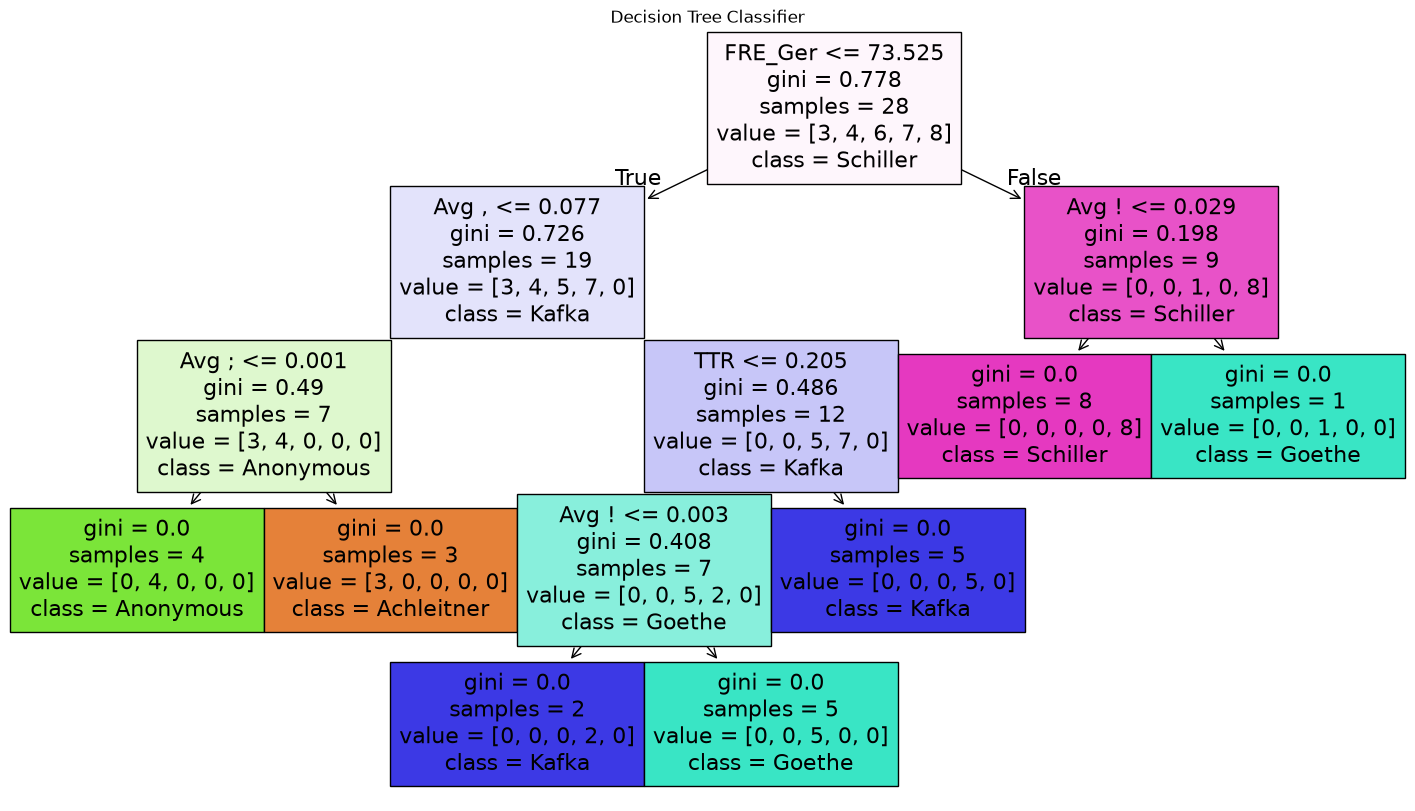

In [11]:
plt.figure(figsize=(18, 10))
tree.plot_tree(clf, filled=True, feature_names=X.columns, class_names=['Achleitner', 'Anonymous', 'Goethe', 'Kafka', 'Schiller'])
plt.title("Decision Tree Classifier")
plt.show()

In [12]:
# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

Accuracy: 0.75


In [13]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

  Achleitner       1.00      1.00      1.00         2
   Anonymous       1.00      0.50      0.67         2
      Goethe       0.50      1.00      0.67         1
       Kafka       0.50      1.00      0.67         1
    Schiller       1.00      0.50      0.67         2

    accuracy                           0.75         8
   macro avg       0.80      0.80      0.73         8
weighted avg       0.88      0.75      0.75         8



In [14]:
k_folds = KFold(n_splits = 10)

scores = cross_val_score(clf, X, y, cv = k_folds)

print("Cross Validation Scores: ", scores)
print("Average CV Score: ", scores.mean())
print("Number of CV Scores used in Average: ", len(scores))

Cross Validation Scores:  [0.25       0.75       0.75       0.         0.75       0.25
 0.33333333 1.         0.66666667 0.33333333]
Average CV Score:  0.5083333333333333
Number of CV Scores used in Average:  10


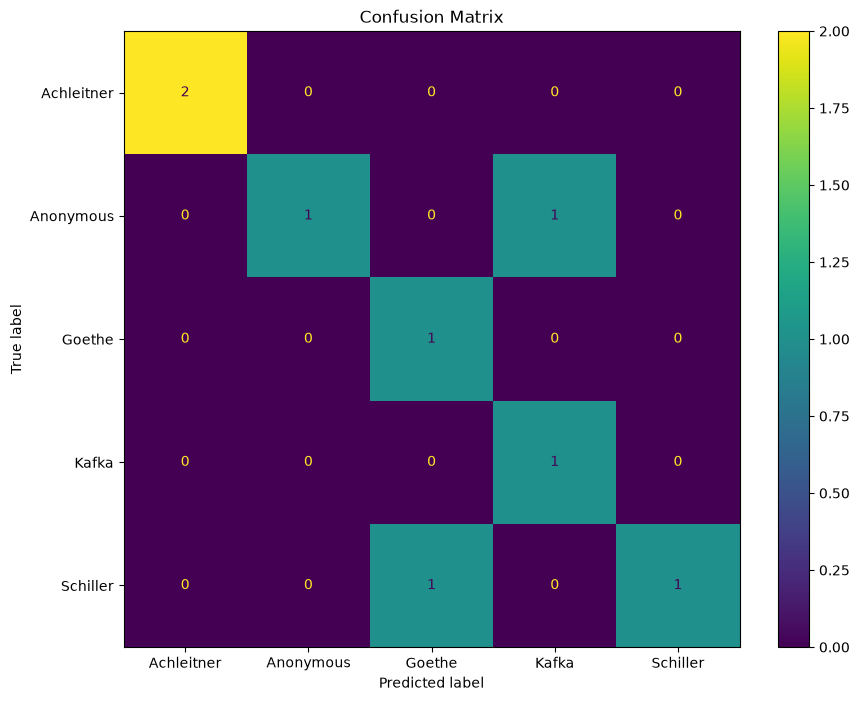

In [15]:
labels = sorted(y.unique())  # all five authors, alphabetical
cm = metrics.confusion_matrix(y_test, y_pred, labels=labels)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)

disp = cm_display.plot()
disp.figure_.set_size_inches(10, 8)
plt.title("Confusion Matrix")
plt.rcParams.update({'font.size': 16})
plt.show()

In [16]:
df_cm_dt = pd.DataFrame()
df_cm_dt["True"] = y_test
df_cm_dt["Predict"] = y_pred
df_cm_dt

,True,Predict
24,Kafka,Kafka
31,Schiller,Schiller
2,Achleitner,Achleitner
12,Goethe,Goethe
7,Anonymous,Anonymous
5,Anonymous,Kafka
32,Schiller,Goethe
3,Achleitner,Achleitner


_______________________

# Random Forest

In [17]:
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

classifier = RandomForestClassifier(n_estimators=1000, random_state=42)
class_fit = classifier.fit(X_train, y_train)
y_pred = class_fit.predict(X_test)

In [18]:
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

Accuracy: 87.50%


In [19]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

  Achleitner       1.00      1.00      1.00         2
   Anonymous       1.00      0.50      0.67         2
      Goethe       1.00      1.00      1.00         1
       Kafka       0.50      1.00      0.67         1
    Schiller       1.00      1.00      1.00         2

    accuracy                           0.88         8
   macro avg       0.90      0.90      0.87         8
weighted avg       0.94      0.88      0.88         8



In [20]:
k_folds = KFold(n_splits = 10)

scores = cross_val_score(classifier, X, y, cv = k_folds)

print("Cross Validation Scores: ", scores)
print("Average CV Score: ", scores.mean())
print("Number of CV Scores used in Average: ", len(scores))

Cross Validation Scores:  [0.5        0.75       1.         0.25       0.5        0.
 0.33333333 1.         1.         1.        ]
Average CV Score:  0.6333333333333333
Number of CV Scores used in Average:  10


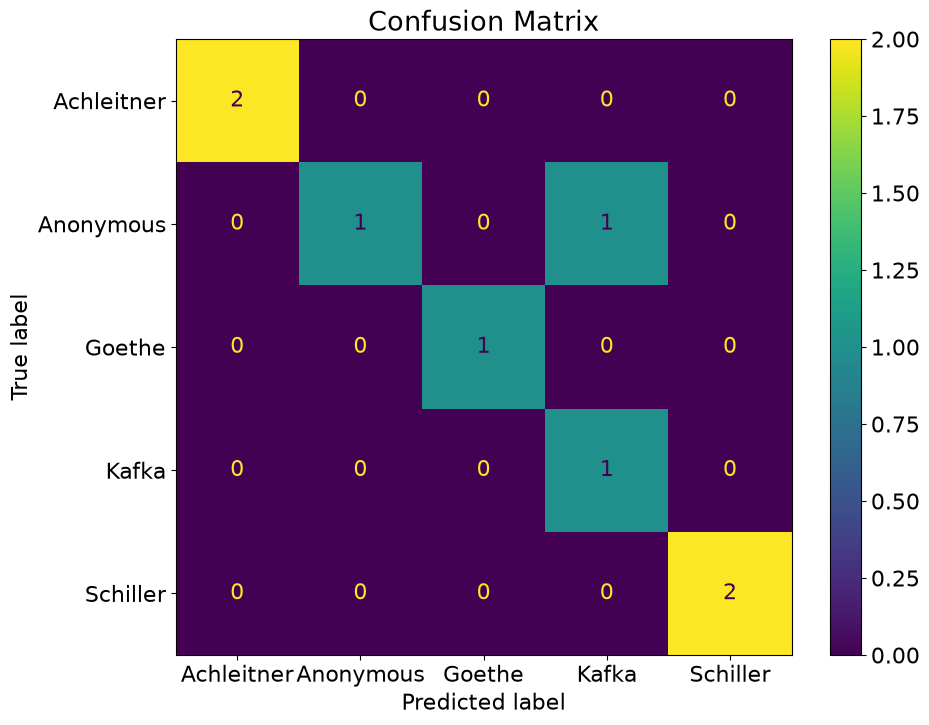

In [21]:
labels = sorted(y.unique())  # all five authors, alphabetical
cm = metrics.confusion_matrix(y_test, y_pred, labels=labels)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)

disp = cm_display.plot()
disp.figure_.set_size_inches(10, 8)
plt.title("Confusion Matrix")
plt.rcParams.update({'font.size': 16})
plt.show()

In [22]:
df_cm_rf = pd.DataFrame()
df_cm_rf["True"] = y_test
df_cm_rf["Predict"] = y_pred
df_cm_rf

,True,Predict
24,Kafka,Kafka
31,Schiller,Schiller
2,Achleitner,Achleitner
12,Goethe,Goethe
7,Anonymous,Anonymous
5,Anonymous,Kafka
32,Schiller,Schiller
3,Achleitner,Achleitner


________________________

# Support Vector Machine

In [23]:
#X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=33, test_size=0.2)

clf = svm.SVC(kernel="linear", gamma=1000, C=1000)
clf_fit = clf.fit(X_train, y_train)
clf_fit.score(X_train, y_train)

1.0

In [24]:
y_pred = clf_fit.predict(X_test)

accuracy = metrics.accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

Accuracy: 87.50%


In [25]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

  Achleitner       1.00      1.00      1.00         2
   Anonymous       1.00      1.00      1.00         2
      Goethe       0.50      1.00      0.67         1
       Kafka       1.00      1.00      1.00         1
    Schiller       1.00      0.50      0.67         2

    accuracy                           0.88         8
   macro avg       0.90      0.90      0.87         8
weighted avg       0.94      0.88      0.88         8



In [26]:
k_folds = KFold(n_splits = 10)

scores = cross_val_score(classifier, X, y, cv = k_folds)

print("Cross Validation Scores: ", scores)
print("Average CV Score: ", scores.mean())
print("Number of CV Scores used in Average: ", len(scores))

Cross Validation Scores:  [0.5        0.75       1.         0.25       0.5        0.
 0.33333333 1.         1.         1.        ]
Average CV Score:  0.6333333333333333
Number of CV Scores used in Average:  10


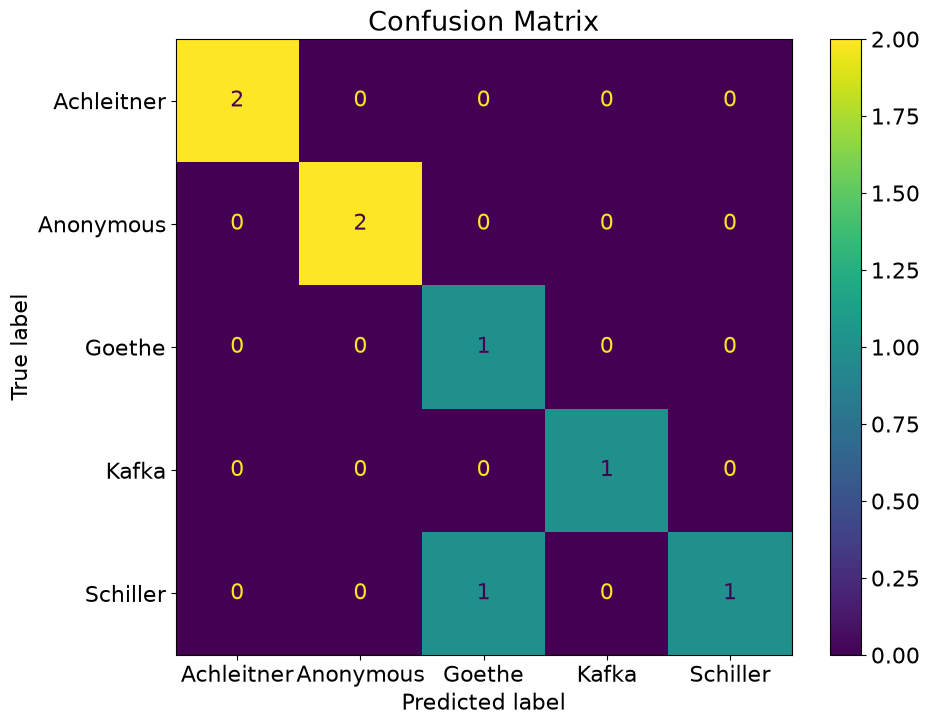

In [27]:
labels = sorted(y.unique())  # all five authors, alphabetical
cm = metrics.confusion_matrix(y_test, y_pred, labels=labels)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)

disp = cm_display.plot()
disp.figure_.set_size_inches(10, 8)
plt.title("Confusion Matrix")
plt.rcParams.update({'font.size': 16})
plt.show()

In [28]:
df_cm_svm = pd.DataFrame()
df_cm_svm["True"] = y_test
df_cm_svm["Predict"] = y_pred
df_cm_svm

,True,Predict
24,Kafka,Kafka
31,Schiller,Schiller
2,Achleitner,Achleitner
12,Goethe,Goethe
7,Anonymous,Anonymous
5,Anonymous,Anonymous
32,Schiller,Goethe
3,Achleitner,Achleitner


------------------

# Predict Ensemble

In [29]:
df_pred_ensemble = pd.DataFrame()
df_pred_ensemble["Decision Tree"] = df_cm_dt["Predict"]
df_pred_ensemble["Random Forest"] = df_cm_rf["Predict"]
df_pred_ensemble["Support Vector Machine"] = df_cm_svm["Predict"]

df_pred_ensemble

,Decision Tree,Random Forest,Support Vector Machine
24,Kafka,Kafka,Kafka
31,Schiller,Schiller,Schiller
2,Achleitner,Achleitner,Achleitner
12,Goethe,Goethe,Goethe
7,Anonymous,Anonymous,Anonymous
5,Kafka,Kafka,Anonymous
32,Goethe,Schiller,Goethe
3,Achleitner,Achleitner,Achleitner


In [30]:
# Funktion zur Ermittlung des Ergebnisnamens
def predEnsemble(row):
    # Wenn Decision Tree und Random Forest übereinstimmen, gib Decision Tree zurück
    if row['Decision Tree'] == row['Random Forest']:
        return row['Decision Tree']
    # Wenn Decision Tree und Support Vector Machine übereinstimmen, gib Decision Tree zurück
    if row['Decision Tree'] == row['Support Vector Machine']:
        return row['Decision Tree']
    # Wenn Random Forest und Support Vector Machine übereinstimmen, gib Random Forest zurück
    if row['Random Forest'] == row['Support Vector Machine']:
        return row['Random Forest']
    # Wenn alle drei unterschiedlich sind, gib Support Vector Machine zurück
    return row['Support Vector Machine']

def colors(row):
    farben = []
    for spalte in ['Decision Tree', 'Random Forest', 'Support Vector Machine']:
        if row[spalte] == row['predEnsemble']:
            farben.append('background-color: green')
        else:
            farben.append('background-color: red')
    farben.append('')  # keine Farbe für 'predEnsemble'
    for spalte in ['predEnsemble']:
        if row[spalte] == row['True Labels']: #Vergleiche predEnsemble mit True Labels
            farben.append('background-color: green')
        else:
            farben.append('background-color: red')
    return farben

# Anwenden der Funktion auf jede Zeile und Speichern in neuer Spalte 'predEnsemble'
df_pred_ensemble['predEnsemble'] = df_pred_ensemble.apply(predEnsemble, axis=1)
df_pred_ensemble["True Labels"] = y_test
erg = df_pred_ensemble.style.apply(colors, axis=1, subset=['Decision Tree', 'Random Forest', 'Support Vector Machine', 'predEnsemble', 'True Labels']).set_properties(**{'text-align': 'center', 'font-size': '20px', 'padding': '10px', 'width': '200px'}).set_table_styles([{'selector': 'th', 'props': [('font-size', '28px'), ('font-weight', 'bold'), ('text-align', 'center')]}])
erg.set_properties(subset=['True Labels'], **{'border': '6px solid lightgreen', 'color': 'white', 'font-size': '22px', 'font-weight': 'bold'})

,Decision Tree,Random Forest,Support Vector Machine,predEnsemble,True Labels
24,Kafka,Kafka,Kafka,Kafka,Kafka
31,Schiller,Schiller,Schiller,Schiller,Schiller
2,Achleitner,Achleitner,Achleitner,Achleitner,Achleitner
12,Goethe,Goethe,Goethe,Goethe,Goethe
7,Anonymous,Anonymous,Anonymous,Anonymous,Anonymous
5,Kafka,Kafka,Anonymous,Kafka,Anonymous
32,Goethe,Schiller,Goethe,Goethe,Schiller
3,Achleitner,Achleitner,Achleitner,Achleitner,Achleitner


In [31]:
corp.to_csv("../data/features.csv", index=False)